# Лінійна регресія: тривалість впливу ДТП

Дані — результат `regression_data_preparation.ipynb` (`data/processed/regression/`): ознаки вже очищені, закодовані й масштабовані, ціль `Log_Duration = log1p(Duration_Minutes)` (тривалість у хвилинах має довгий правий хвіст; у лог-шкалі розподіл близький до симетричного).

**Модель — `pyspark.ml.regression.LinearRegression`** (метод найменших квадратів; у Spark — з опційною регуляризацією L2 / L1 / elastic net). Для порівняння — baseline: прогноз середнім train.

**Етапи:**
1. Завантаження (`spark.read.parquet` → `VectorAssembler`) та експрес-перевірка даних.
2. Гіперпараметри: `regParam` і `elasticNetParam` (МНК / Ridge / Lasso) — `CrossValidator`, 5 фолдів на стратифікованій підвибірці train.
3. Навчання на повному train; таблиця метрик на train.
4. Valid: таблиця метрик, графіки train vs valid (Actual vs Predicted, залишки).
5. Test: фінальна оцінка.
6. SHAP: beeswarm і bar chart важливості ознак.

**Усі обчислення — у Spark:** навчання, прогнози, метрики (одна агрегація на вибірку), гістограма залишків, таблиця за діапазонами тривалості. На драйвер потрапляють лише підсумки, а pandas / numpy — тільки для їх показу, для графіків (на 200 000 випадкових записів) і для SHAP (на 5 000 записах).

Запуск — у Docker (`docker compose up`): Spark на Windows без `winutils.exe` не читає parquet.

## Етап 1. Завантаження та експрес-перевірка даних

In [1]:
import os
import sys
import json
import time
from pathlib import Path

PROJECT_ROOT = Path.cwd() if (Path.cwd() / "main.py").exists() else Path.cwd().parent
os.environ["PYSPARK_PYTHON"] = sys.executable
os.environ["PYSPARK_DRIVER_PYTHON"] = sys.executable
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
import joblib
from IPython.display import display

from pyspark.sql import SparkSession, Window, functions as F
from pyspark.ml.feature import VectorAssembler
from pyspark.ml.functions import vector_to_array
from pyspark.ml.stat import Summarizer

SEED = 42
# Частка train (для швидкої перевірки на слабкій машині); 1 — весь train
TRAIN_FRACTION = float(os.environ.get("TRAIN_FRACTION", "1"))
DATA_DIR = PROJECT_ROOT / "data" / "processed" / "regression"
MODELS_DIR = PROJECT_ROOT / "data" / "models"
MODELS_DIR.mkdir(parents=True, exist_ok=True)
sns.set_theme(style="whitegrid")
pd.set_option("display.width", 200)
pd.set_option("display.max_columns", 30)

spark = (
    SparkSession.builder
    .appName("US-Accidents-regression-model")
    .master("local[*]")
    .config("spark.driver.memory", os.environ.get("SPARK_DRIVER_MEMORY", "16g"))
    .config("spark.driver.host", "localhost")
    .config("spark.sql.shuffle.partitions", "48")
    # shuffle — у файловій системі контейнера: у змонтованій з Windows теці проекту кожна ітерація L-BFGS у 2–3 рази повільніша
    .config("spark.local.dir", os.environ.get("SPARK_LOCAL_DIR", "/tmp/spark-tmp"))
    .config("spark.sql.execution.arrow.pyspark.enabled", "true")
    .config("spark.ui.showConsoleProgress", "false")
    .getOrCreate()
)
spark.sparkContext.setLogLevel("ERROR")
print("Spark", spark.version)

meta = json.loads((DATA_DIR / "metadata.json").read_text(encoding="utf-8"))
FEATURES = meta["feature_names"]
COLS = [f"f{i}" for i in range(len(FEATURES))]   # назви ознак містять «.», «[», пробіли — у Spark працюємо з f0…f243
TARGETS = ["Log_Duration", "Duration_Minutes"]
ASSEMBLER = VectorAssembler(inputCols=COLS, outputCol="features", handleInvalid="keep")   # NaN не падають тут — рахуємо їх нижче


def load(split, fraction=1.0):
    df = spark.read.parquet(str(DATA_DIR / split)).select(
        *[F.col(f"`{name}`").alias(c) for name, c in zip(FEATURES, COLS)], *[F.col(t).cast("double") for t in TARGETS])
    if fraction < 1:
        df = df.sample(fraction=fraction, seed=SEED)
    return ASSEMBLER.transform(df).select("features", *TARGETS)


t0 = time.time()
SPLITS = {"train": load("train", TRAIN_FRACTION), "valid": load("valid"), "test": load("test")}
N = {split: df.count() for split, df in SPLITS.items()}
train, valid, test = SPLITS.values()
print(", ".join(f"{split} {n:,}" for split, n in N.items()) + f"{f' ({TRAIN_FRACTION:.0%} train)' if TRAIN_FRACTION < 1 else ''}; "
      f"ознак: {len(FEATURES)} — {time.time() - t0:.0f} c")

Using Spark's default log4j profile: org/apache/spark/log4j2-defaults.properties
Setting default log level to "WARN".
To adjust logging level use sc.setLogLevel(newLevel). For SparkR, use setLogLevel(newLevel).


26/10/29 15:50:34 WARN NativeCodeLoader: Unable to load native-hadoop library for your platform... using builtin-java classes where applicable
26/10/29 15:50:34 WARN SparkConf: Note that spark.local.dir will be overridden by the value set by the cluster manager (via SPARK_LOCAL_DIRS in standalone/kubernetes and LOCAL_DIRS in YARN).


Spark 4.1.1


train 4,496,355, valid 642,217, test 1,282,718; ознак: 244 — 12 c


Вибірки — ліниві Spark DataFrame поверх parquet (стовпчиковий стиснений формат, 359 МБ train), тож кожен прохід читає файли заново, а не тримає ~9 ГБ матриці в пам'яті. Ознаки зібрані `VectorAssembler` у стовпець `features`.

Перевірка — один прохід `Summarizer` по вектору ознак: середнє, std, мінімум і максимум кожної ознаки (показано перші й останні). Пропуски (NaN) зробили б середнє ознаки NaN, тож рахуємо такі ознаки. Наприкінці — розподіл цілі на трьох вибірках (`DataFrame.summary`).

In [2]:
STATS = ["mean", "std", "min", "max"]
for split, df in SPLITS.items():
    print(f"\n{'=' * 30} {split}: {N[split]:,} записів × {len(FEATURES)} ознак {'=' * 30}")
    display(df.limit(5).select(vector_to_array("features").alias("x"), *TARGETS)
            .select(*[F.col("x")[i].alias(FEATURES[i]) for i in range(10)], *TARGETS).toPandas())
    s = df.select(Summarizer.metrics(*STATS).summary(F.col("features")).alias("s")).first()["s"]
    desc = pd.DataFrame({m: s[m].toArray() for m in STATS}, index=FEATURES)
    print(f"ознак з пропусками (NaN): {int(desc['mean'].isna().sum())}")
    display(pd.concat([desc.head(8), desc.tail(8)]).round(4))


============================== train: 4,496,355 записів × 244 ознак ==============================


,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),TE_Street_t_sev1,TE_Street_t_sev3,Log_Duration,Duration_Minutes
0,-0.364908,-1.367240,-0.557499,1.399576,-2.239511,-0.453527,0.41542,0.522875,-0.087410,2.406521,4.110874,60.00
1,0.545562,0.018898,-0.557499,1.825403,-1.230013,-0.785868,0.41542,0.901375,-0.546831,0.145413,3.410157,29.27
2,1.133219,0.417321,-0.557499,0.122094,-0.659428,-0.183500,0.41542,-0.423373,1.573645,-0.387692,4.119362,60.52
3,-0.009973,0.465663,-0.557499,1.186662,-1.186122,-0.183500,0.41542,-0.423373,1.118648,-0.654862,3.827554,44.95
4,0.304553,-1.562820,-0.557499,1.825403,-2.283402,-0.090029,0.41542,0.522875,0.423046,1.434392,4.762174,116.00


ознак з пропусками (NaN): 0


,mean,std,min,max
Start_Lat,0.0000,1.0000,-2.3152,2.5462
Start_Lng,0.0000,1.0000,-1.7131,1.5801
Distance(mi),-0.0000,1.0000,-0.5575,4.6616
Temperature(F),0.0000,1.0000,-2.9652,1.9851
Humidity(%),-0.0000,1.0000,-2.4590,1.5351
Pressure(in),0.0000,1.0000,-5.5425,1.0109
Visibility(mi),0.0000,1.0000,-3.7610,0.4154
Wind_Speed(mph),-0.0000,1.0000,-1.3696,3.3616
"Wind_Speed(mph) in [0, 3)",0.1780,0.3825,0.0000,1.0000
"Wind_Speed(mph) in [3, 4.6)",0.0962,0.2949,0.0000,1.0000



============================== valid: 642,217 записів × 244 ознак ==============================


...

,mean,std,min,max
Start_Lat,-0.0003,0.9991,-2.3142,2.5457
Start_Lng,-0.0001,1.0003,-1.7124,1.5671
Distance(mi),-0.0019,0.9974,-0.5575,4.6616
Temperature(F),0.0001,0.9984,-2.9652,1.9851
Humidity(%),0.0006,0.9998,-2.4590,1.5351
Pressure(in),0.0011,0.9991,-5.5425,1.0109
Visibility(mi),0.0009,0.9991,-3.7610,0.4154
Wind_Speed(mph),0.0004,1.0012,-1.3696,3.3616
"Wind_Speed(mph) in [0, 3)",0.1780,0.3825,0.0000,1.0000
"Wind_Speed(mph) in [3, 4.6)",0.0969,0.2958,0.0000,1.0000



============================== test: 1,282,718 записів × 244 ознак ==============================


,Start_Lat,Start_Lng,Distance(mi),Temperature(F),Humidity(%),Pressure(in),Visibility(mi),Wind_Speed(mph),TE_Street_t_sev1,TE_Street_t_sev3,Log_Duration,Duration_Minutes
0,1.723178,0.092821,-0.557499,1.399576,-0.834993,-0.702783,0.41542,-0.044874,-0.569214,0.215828,4.104790,59.63
1,-0.691311,-0.113309,-0.557499,1.772175,-1.230013,-0.360056,0.41542,0.522875,-0.627862,1.764265,3.819469,44.58
2,1.402575,0.549788,-0.557499,-0.303734,0.130614,-0.297742,0.41542,-0.801872,1.902992,-0.268564,4.339902,75.70
3,-0.562288,0.738058,-0.557499,0.441464,0.701199,0.221541,0.41542,-0.234123,1.486428,-0.978912,4.105449,59.67
4,0.778386,0.682780,1.247776,0.760835,-0.878884,-0.557384,0.41542,1.469123,-0.636857,1.877434,3.844172,45.72


ознак з пропусками (NaN): 0


,mean,std,min,max
Start_Lat,0.0004,1.0000,-2.3152,2.5465
Start_Lng,-0.0012,1.0009,-1.7175,1.5761
Distance(mi),-0.0017,0.9965,-0.5575,4.6616
Temperature(F),-0.0023,0.9991,-2.9652,1.9851
Humidity(%),0.0031,0.9996,-2.4590,1.5351
Pressure(in),0.0018,0.9955,-5.5425,1.0109
Visibility(mi),-0.0011,1.0013,-3.7610,0.4154
Wind_Speed(mph),-0.0002,0.9989,-1.3696,3.3616
"Wind_Speed(mph) in [0, 3)",0.1775,0.3821,0.0000,1.0000
"Wind_Speed(mph) in [3, 4.6)",0.0967,0.2955,0.0000,1.0000


In [3]:
pd.concat({split: df.select(*TARGETS).summary("count", "mean", "stddev", "min", "25%", "50%", "75%", "max")
           .toPandas().set_index("summary").astype(float) for split, df in SPLITS.items()}, axis=1).round(3)

train                         valid                          test                 
        Log_Duration Duration_Minutes Log_Duration Duration_Minutes Log_Duration Duration_Minutes
summary                                                                                          
count    4496355.000      4496355.000   642217.000       642217.000  1282718.000      1282718.000
mean           4.172           84.940        4.169           84.690        4.170           84.821
stddev         0.709           82.067        0.708           81.746        0.709           81.856
min            0.798            1.220        1.609            4.000        1.072            1.920
25%            3.430           29.870        3.430           29.870        3.430           29.870
50%            4.110           59.950        4.109           59.880        4.109           59.900
75%            4.658          104.420        4.654          104.030        4.657          104.350
max            6.610          741.500        6.610          741.500        6.610          741.500

## Етап 2. Гіперпараметри та крос-валідація

На відміну від `LinearRegression` у scikit-learn, у Spark є регуляризація: **`regParam`** ($\lambda$, сила штрафу) і **`elasticNetParam`** ($\alpha$: 0 — L2 / Ridge, 1 — L1 / Lasso). Сітка: звичайний МНК ($\lambda = 0$), Ridge і Lasso з $\lambda$ = 10⁻³, 10⁻², 10⁻¹. Очікування — регуляризація не потрібна: записів (~4.5 млн) у ~20 000 разів більше, ніж ознак, тож оцінки коефіцієнтів стабільні; це перевіряємо і пошуком, і порівнянням train / valid / test.

**`CrossValidator`, 5 фолдів на підвибірці ~100 000 записів (~2% train)**, стратифікованій за **децилями цілі** (`approxQuantile` → `Bucketizer` → `sampleBy`): частки коротких, типових і довгих подій такі самі, як у train; номер фолду призначаємо всередині кожного децилю, тож фолди теж стратифіковані. Відбір — за RMSE у лог-шкалі. `CrossValidator` повертає лише одну метрику, тому зберігаємо моделі фолдів (`collectSubModels=True`) і для кожної рахуємо RMSE, MAE та R² на її валідаційному фолді; baseline — середнє train-частини фолду.

In [4]:
from pyspark.ml.feature import Bucketizer
from pyspark.ml.regression import LinearRegression
from pyspark.ml.evaluation import RegressionEvaluator
from pyspark.ml.tuning import CrossValidator


def metrics(pred, scales=("log", "хв")):
    """pred: Log_Duration, Duration_Minutes, prediction (у лог-шкалі). Усі метрики — одна агрегація Spark;
    MedAE — percentile_approx (точність 10⁻⁴ за рангом)."""
    pred = pred.withColumn("pred_min", F.expm1("prediction"))
    columns = {"log": ("Log_Duration", "prediction"), "хв": ("Duration_Minutes", "pred_min")}
    aggs = []
    for i, scale in enumerate(scales):
        y, p = columns[scale]
        err = F.col(y) - F.col(p)
        aggs += [F.avg(err ** 2).alias(f"mse{i}"), F.avg(F.abs(err)).alias(f"mae{i}"), F.var_pop(y).alias(f"var{i}"),
                 F.avg(F.abs(err / F.col(y))).alias(f"mape{i}"), F.percentile_approx(F.abs(err), 0.5, 10_000).alias(f"medae{i}")]
    r = pred.agg(*aggs).first()
    out = {}
    for i, scale in enumerate(scales):
        out.update({f"R² ({scale})": 1 - r[f"mse{i}"] / r[f"var{i}"], f"MAE ({scale})": r[f"mae{i}"],
                    f"MSE ({scale})": r[f"mse{i}"], f"RMSE ({scale})": r[f"mse{i}"] ** 0.5,
                    f"MAPE, % ({scale})": 100 * r[f"mape{i}"], f"MedAE ({scale})": r[f"medae{i}"]})
    return out


DECILE_SPLITS = sorted({-float("inf"), float("inf"),
                        *train.approxQuantile("Log_Duration", [i / 10 for i in range(1, 10)], 1e-4)})   # однакові межі зливаються
DECILES = Bucketizer(splits=DECILE_SPLITS, inputCol="Log_Duration", outputCol="decile")

TUNE_ROWS = 100_000
fraction = min(1.0, TUNE_ROWS / N["train"])
tune = (DECILES.transform(train)
        .sampleBy("decile", {float(d): fraction for d in range(len(DECILE_SPLITS) - 1)}, seed=SEED)
        .withColumn("fold", F.row_number().over(Window.partitionBy("decile").orderBy(F.rand(SEED))) % 5)
        .repartition(spark.sparkContext.defaultParallelism)   # після вікна за decile дані лежать у кількох розділах — розподіляємо по всіх ядрах
        .cache())
N_TUNE = tune.count()
print(f"Підвибірка для крос-валідації: {N_TUNE:,} записів ({100 * N_TUNE / N['train']:.1f}% train), децилів: {len(DECILE_SPLITS) - 1}")

lr = LinearRegression(labelCol="Log_Duration")
GRID = [{lr.regParam: 0.0, lr.elasticNetParam: 0.0}] + [{lr.regParam: reg, lr.elasticNetParam: alpha}
                                                       for alpha in (0.0, 1.0) for reg in (1e-3, 1e-2, 1e-1)]


def grid_name(params):
    reg, alpha = params[lr.regParam], params[lr.elasticNetParam]
    return "МНК (regParam = 0)" if reg == 0 else f"{'Ridge' if alpha == 0 else 'Lasso'} (regParam = {reg:g})"


t0 = time.time()
search = CrossValidator(estimator=lr, estimatorParamMaps=GRID, evaluator=RegressionEvaluator(labelCol="Log_Duration", metricName="rmse"),
                        foldCol="fold", numFolds=5, collectSubModels=True, parallelism=4, seed=SEED).fit(tune)

fold_scores = []
for i in range(5):
    fold_valid = tune.filter(F.col("fold") == i)
    fold_mean = tune.filter(F.col("fold") != i).agg(F.avg("Log_Duration")).first()[0]
    fold_scores.append({"модель": "Baseline (середнє)", **metrics(fold_valid.withColumn("prediction", F.lit(fold_mean)), ("log",))})
    for params, sub in zip(GRID, search.subModels[i]):
        fold_scores.append({"модель": grid_name(params), **metrics(sub.transform(fold_valid), ("log",))})
tune.unpersist()

best_params = {p.name: v for p, v in GRID[int(np.argmin(search.avgMetrics))].items()}
print(f"Пошук: {time.time() - t0:.0f} c; найкращі параметри за RMSE (CV): {best_params}")
cv = pd.DataFrame(fold_scores).groupby("модель", sort=False)
pd.DataFrame({"RMSE log (CV)": cv["RMSE (log)"].mean(), "std RMSE": cv["RMSE (log)"].std(ddof=0),
              "MAE log (CV)": cv["MAE (log)"].mean(), "R² (CV)": cv["R² (log)"].mean(), "std R²": cv["R² (log)"].std(ddof=0)}).round(4)

Підвибірка для крос-валідації: 99,915 записів (2.2% train), децилів: 10


Пошук: 30 c; найкращі параметри за RMSE (CV): {'regParam': 0.001, 'elasticNetParam': 0.0}


,RMSE log (CV),std RMSE,MAE log (CV),R² (CV),std R²
модель,,,,,
Baseline (середнє),0.7079,0.0011,0.5823,-0.0000,0.0000
МНК (regParam = 0),0.6098,0.0797,0.4229,0.2452,0.2130
Ridge (regParam = 0.001),0.5697,0.0014,0.4219,0.3523,0.0041
Ridge (regParam = 0.01),0.5698,0.0014,0.4223,0.3519,0.0042
Ridge (regParam = 0.1),0.5718,0.0013,0.4259,0.3476,0.0041
Lasso (regParam = 0.001),0.5698,0.0014,0.4221,0.3519,0.0042
Lasso (regParam = 0.01),0.5753,0.0015,0.4279,0.3396,0.0041
Lasso (regParam = 0.1),0.6331,0.0008,0.4930,0.2002,0.0020


## Етап 3. Навчання та первинне оцінювання

На повному train навчаємо `LinearRegression` з параметрами, найкращими за CV (і baseline — середнє train — для порівняння).

**Як Spark рахує МНК на мільйонах записів.** Для $\lambda = 0$ або L2 `solver="auto"` обирає `"normal"` — нормальні рівняння (`WeightedLeastSquares`): за **один розподілений прохід** по даних кожен розділ накопичує суми $X^\top X$ (244 × 244), $X^\top y$, $\sum x$, $\sum y$, які потім додаються; систему розв'язує драйвер (розклад Холецького; якщо $X^\top X$ вироджена — квазіньютонівський метод). Уся матриця train ніде не зберігається в пам'яті, тож порційне навчання, яке було потрібне для scikit-learn, тут не потрібне. Для L1 (Lasso) Spark переходить на ітеративний OWL-QN.

`standardization=True` (за замовчуванням) впливає лише на штраф регуляризації; для $\lambda = 0$ розв'язок той самий, що й без неї.

**Метрики** — у лог-шкалі (в ній модель навчалась) і **в хвилинах** (прогноз = `expm1(прогноз)`): R², MAE, MSE, RMSE, MAPE (тривалість ≥ 1 хв, тож ділення на нуль немає), MedAE (медіанна похибка — типова, нечутлива до хвоста). Прогноз `expm1(ŷ)` оцінює **медіану** тривалості для таких умов, а не середнє, тому MedAE у хвилинах — найчесніша метрика в хвилинах. Усі метрики вибірки рахує одна агрегація Spark.

In [5]:
t0 = time.time()
model = lr.copy({lr.getParam(name): value for name, value in best_params.items()}).fit(train)
y_mean = train.agg(F.avg("Log_Duration")).first()[0]
print(f"LinearRegression ({best_params}, solver={model.getSolver()}) навчено за {time.time() - t0:.0f} c; "
      f"середнє train (baseline): {y_mean:.4f}")
MODELS = {"Baseline (середнє)": lambda df: df.withColumn("prediction", F.lit(y_mean)), "LinearRegression": model.transform}


def metrics_table(df):
    return pd.DataFrame({name: metrics(predict(df)) for name, predict in MODELS.items()}).T.rename_axis("модель")


results_train = metrics_table(train)
results_train.round(4)

LinearRegression ({'regParam': 0.001, 'elasticNetParam': 0.0}, solver=auto) навчено за 46 c; середнє train (baseline): 4.1717


,R² (log),MAE (log),MSE (log),RMSE (log),"MAPE, % (log)",MedAE (log),R² (хв),MAE (хв),MSE (хв),RMSE (хв),"MAPE, % (хв)",MedAE (хв)
модель,,,,,,,,,,,,
Baseline (середнє),0.0000,0.5832,0.5028,0.7091,14.2787,0.6241,-0.0662,48.1264,7180.6908,84.7390,64.9556,34.0266
LinearRegression,0.3533,0.4225,0.3252,0.5702,10.4235,0.3076,0.2013,37.7161,5379.3661,73.3442,50.4718,19.3977


## Етап 4. Оцінювання на валідації

Valid не бере участі в навчанні — близькі метрики train і valid означають, що перенавчання немає.

**Графіки train vs valid** (у лог-шкалі; для читабельності — ~200 000 випадкових записів кожної вибірки, які Spark відбирає `sample` і передає на драйвер; щільність точок — колір):
* **Actual vs Predicted** — ідеальний прогноз лежить на діагоналі;
* **Residual plot** — залишок $y - \hat y$ проти прогнозу: без тренду й з однаковим розкидом, якщо модель не має систематичних помилок.

In [6]:
results_valid = metrics_table(valid)
results_valid.round(4)

,R² (log),MAE (log),MSE (log),RMSE (log),"MAPE, % (log)",MedAE (log),R² (хв),MAE (хв),MSE (хв),RMSE (хв),"MAPE, % (хв)",MedAE (хв)
модель,,,,,,,,,,,,
Baseline (середнє),-0.000,0.5829,0.5018,0.7084,14.2844,0.6242,-0.0651,47.9708,7117.7751,84.3669,65.0419,34.0266
LinearRegression,0.353,0.4224,0.3247,0.5698,10.4278,0.3080,0.2030,37.6099,5325.9348,72.9790,50.5525,19.3808


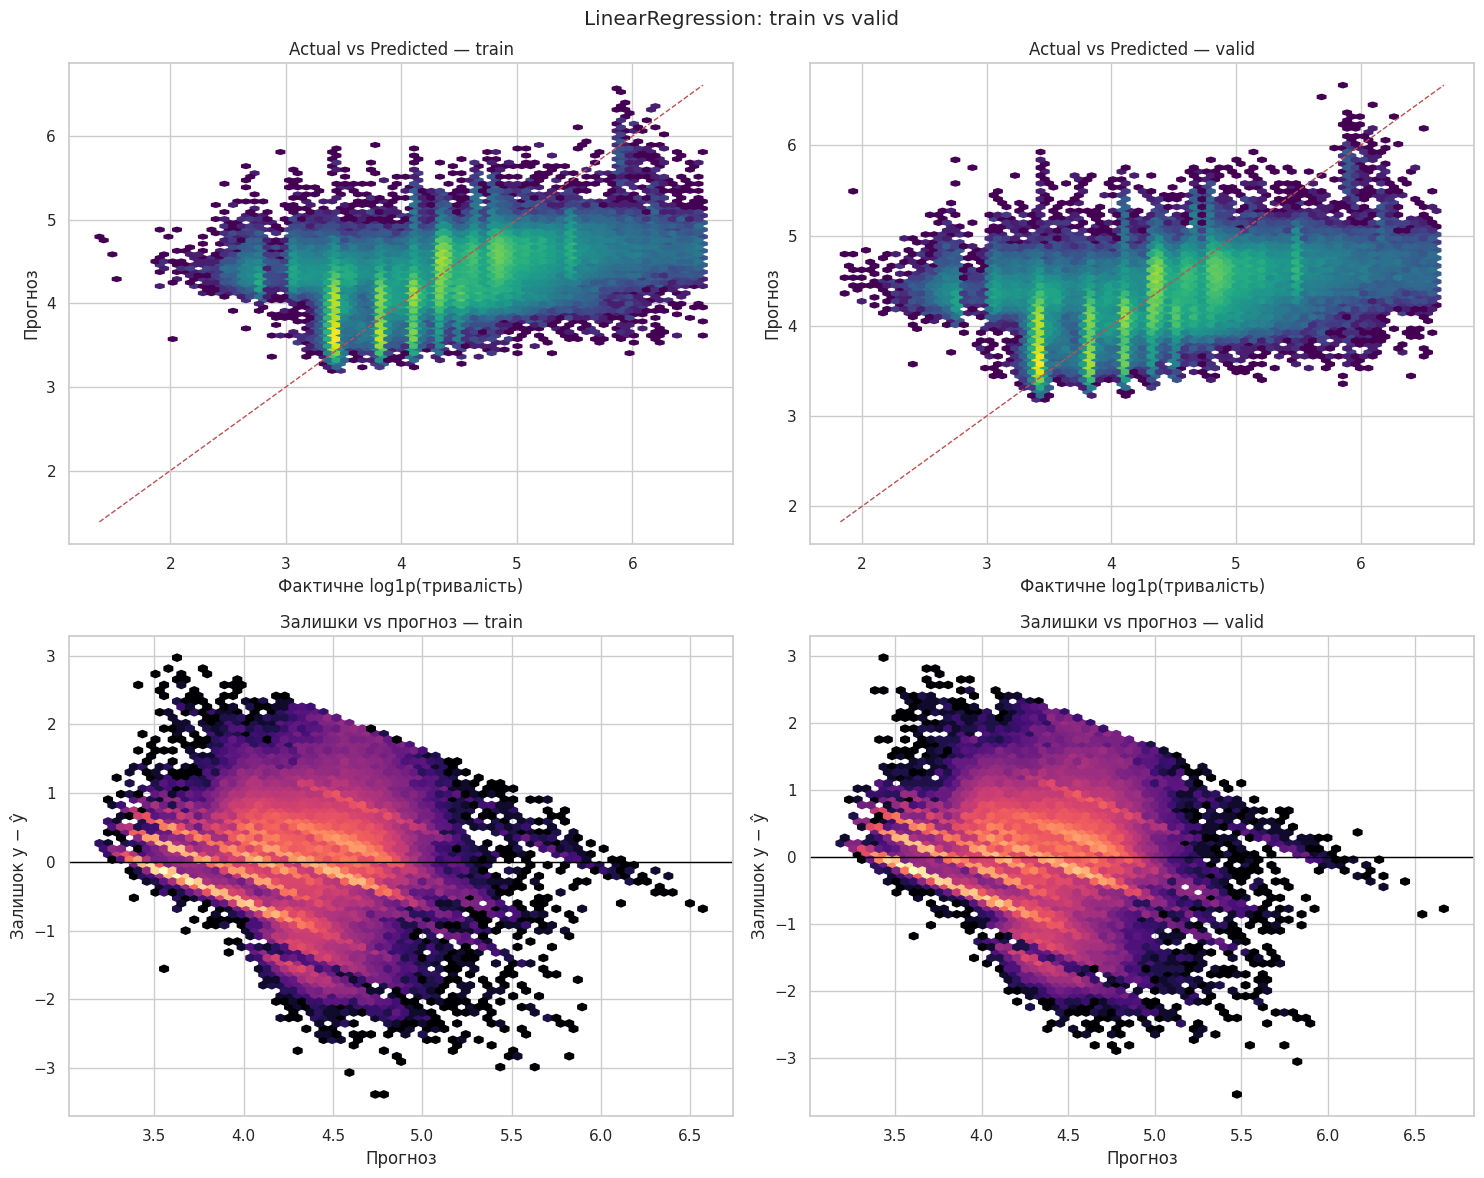

In [7]:
def sample_pred(split, size=200_000):
    pdf = (model.transform(SPLITS[split].sample(fraction=min(1.0, size / N[split]), seed=SEED))
           .select("Log_Duration", "prediction").toPandas())
    return pdf["Log_Duration"].to_numpy(), pdf["prediction"].to_numpy()


def plot_actual_vs_pred(ax, y, pred, title):
    ax.hexbin(y, pred, gridsize=70, bins="log", cmap="viridis", mincnt=1)
    lims = [min(y.min(), pred.min()), max(y.max(), pred.max())]
    ax.plot(lims, lims, "r--", lw=1)
    ax.set(title=title, xlabel="Фактичне log1p(тривалість)", ylabel="Прогноз")


def plot_residuals(ax, y, pred, title):
    ax.hexbin(pred, y - pred, gridsize=70, bins="log", cmap="magma", mincnt=1)
    ax.axhline(0, color="black", lw=1)
    ax.set(title=title, xlabel="Прогноз", ylabel="Залишок y − ŷ")


preds = {split: sample_pred(split) for split in ["train", "valid"]}
fig, axes = plt.subplots(2, 2, figsize=(15, 12))
for col, split in enumerate(["train", "valid"]):
    plot_actual_vs_pred(axes[0, col], *preds[split], f"Actual vs Predicted — {split}")
    plot_residuals(axes[1, col], *preds[split], f"Залишки vs прогноз — {split}")
fig.suptitle("LinearRegression: train vs valid")
plt.tight_layout()
plt.show()

## Етап 5. Фінальне оцінювання на тестовій вибірці

Test використовуємо один раз — для навченої моделі (поруч baseline). Це чесна оцінка якості на нових даних.

In [8]:
results_test = metrics_table(test)
results_test.round(4)

,R² (log),MAE (log),MSE (log),RMSE (log),"MAPE, % (log)",MedAE (log),R² (хв),MAE (хв),MSE (хв),RMSE (хв),"MAPE, % (хв)",MedAE (хв)
модель,,,,,,,,,,,,
Baseline (середнє),-0.0000,0.5837,0.5031,0.7093,14.3005,0.6255,-0.0658,48.0819,7141.2023,84.5056,65.1098,34.0266
LinearRegression,0.3524,0.4229,0.3258,0.5708,10.4421,0.3077,0.2022,37.6781,5345.6112,73.1137,50.6563,19.4131


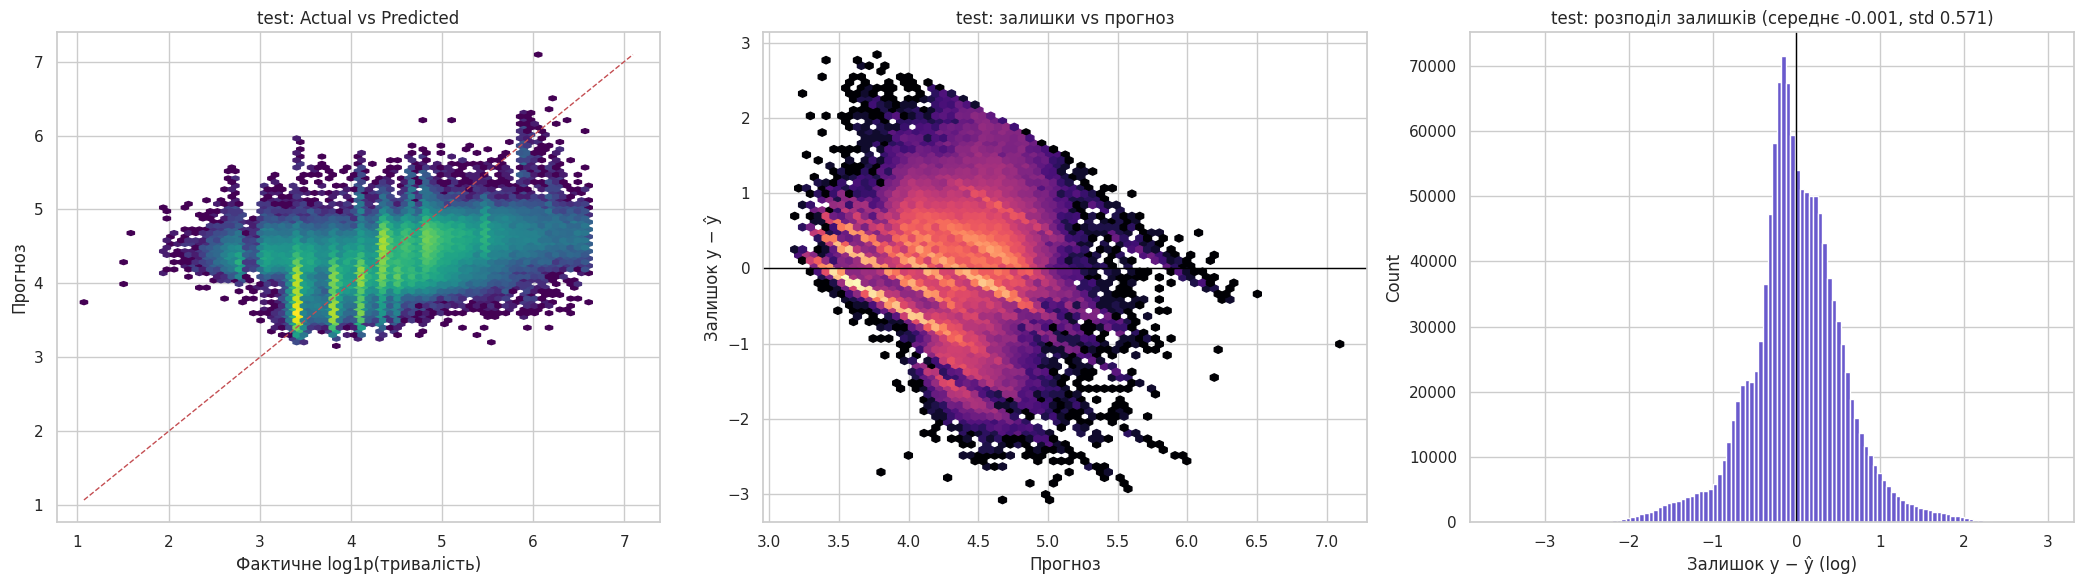

In [9]:
pred_test = (model.transform(test).select("Log_Duration", "Duration_Minutes", "prediction")
             .withColumn("resid", F.col("Log_Duration") - F.col("prediction")).cache())
r = pred_test.agg(F.avg("resid").alias("mean"), F.stddev("resid").alias("std"), F.min("resid").alias("lo"), F.max("resid").alias("hi")).first()
BINS = 120
width = (r["hi"] - r["lo"]) / BINS
hist = (pred_test.groupBy(F.least(F.floor((F.col("resid") - r["lo"]) / width), F.lit(BINS - 1)).alias("b")).count()
        .orderBy("b").toPandas())

fig, axes = plt.subplots(1, 3, figsize=(21, 6))
y_s, p_s = sample_pred("test")
plot_actual_vs_pred(axes[0], y_s, p_s, "test: Actual vs Predicted")
plot_residuals(axes[1], y_s, p_s, "test: залишки vs прогноз")
axes[2].bar(r["lo"] + (hist["b"] + 0.5) * width, hist["count"], width=width, color="slateblue")
axes[2].axvline(0, color="black", lw=1)
axes[2].set(title=f"test: розподіл залишків (середнє {r['mean']:+.3f}, std {r['std']:.3f})", xlabel="Залишок y − ŷ (log)", ylabel="Count")
plt.tight_layout()
plt.show()

In [10]:
RANGES = [(30, "≤30"), (60, "30–60"), (120, "60–120"), (240, "120–240"), (480, "240–480"), (float("inf"), ">480")]
minutes = F.col("Duration_Minutes")
bucket = F.coalesce(*[F.when(minutes <= hi, F.lit(k)) for k, (hi, _) in enumerate(RANGES)])
by_range = (pred_test.groupBy(bucket.alias("k"))
            .agg(F.count("*").alias("записів"), F.percentile_approx(minutes, 0.5, 10_000).alias("медіана_факт"),
                 F.percentile_approx(F.expm1("prediction"), 0.5, 10_000).alias("медіана_прогноз"))
            .withColumn("частка_pct", F.round(100 * F.col("записів") / F.sum("записів").over(Window.partitionBy()), 1))
            .orderBy("k").toPandas())
pred_test.unpersist()
by_range.assign(k=[RANGES[k][1] for k in by_range["k"]]).set_index("k").rename_axis("діапазон, хв").round(1)

,записів,медіана_факт,медіана_прогноз,частка_pct
"діапазон, хв",,,,
≤30,353040,29.6,42.4,27.5
30–60,300225,45.0,51.8,23.4
60–120,361280,79.2,78.4,28.2
120–240,216808,142.5,94.2,16.9
240–480,40237,310.5,101.9,3.1
>480,11128,591.4,103.7,0.9


In [11]:
COLS_SUMMARY = ["R² (log)", "RMSE (log)", "MAE (log)", "MAE (хв)", "MedAE (хв)", "MAPE, % (хв)"]
pd.DataFrame({split: table.loc["LinearRegression", COLS_SUMMARY]
              for split, table in [("train", results_train), ("valid", results_valid), ("test", results_test)]}).T.round(4)

,R² (log),RMSE (log),MAE (log),MAE (хв),MedAE (хв),"MAPE, % (хв)"
train,0.3533,0.5702,0.4225,37.7161,19.3977,50.4718
valid,0.3530,0.5698,0.4224,37.6099,19.3808,50.5525
test,0.3524,0.5708,0.4229,37.6781,19.4131,50.6563


## Етап 6. SHAP-аналіз та інтерпретованість

**SHAP** розкладає кожен прогноз на внески ознак: прогноз (у лог-шкалі) = базове значення (середній прогноз) + сума внесків. Внесок +0.1 ≈ тривалість ×1.105. Для лінійної моделі з незалежними ознаками внесок ознаки $j$ дорівнює рівно $\beta_j\,(x_j - \bar x_j)$: `shap.LinearExplainer` отримує коефіцієнти Spark-моделі (`coefficients`, `intercept`), маскер `Independent` — середні з 2 000 записів train. На відміну від самих коефіцієнтів, SHAP враховує, як часто й наскільки ознака відхиляється від середнього (рідкісна категорія з великим коефіцієнтом впливає на мало записів).

**Вибірка:** ~5 000 записів test, **стратифікованих за децилями цілі** (`sampleBy` за децилями з етапу 2) — короткі й довгі події представлені в тих самих частках, що й у test; рахувати SHAP на всіх 1.3 млн записів немає потреби. Обидві вибірки Spark відбирає й передає на драйвер як numpy-матриці — SHAP працює лише з ними. Сума внесків звіряється з прогнозом Spark.

* **Bar chart** — середній |SHAP|: ліворуч окремі стовпці матриці ознак, праворуч вихідні ознаки (внески one-hot категорій і бінів однієї ознаки додаються: `State`, `Distance(mi)` = значення + біни тощо);
* **Beeswarm** — кожна точка — запис, положення — внесок, колір — значення ознаки.

/usr/local/lib/python3.11/site-packages/tqdm/auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


Фон: 2,000 записів train; вибірка SHAP: 5,092 записів test


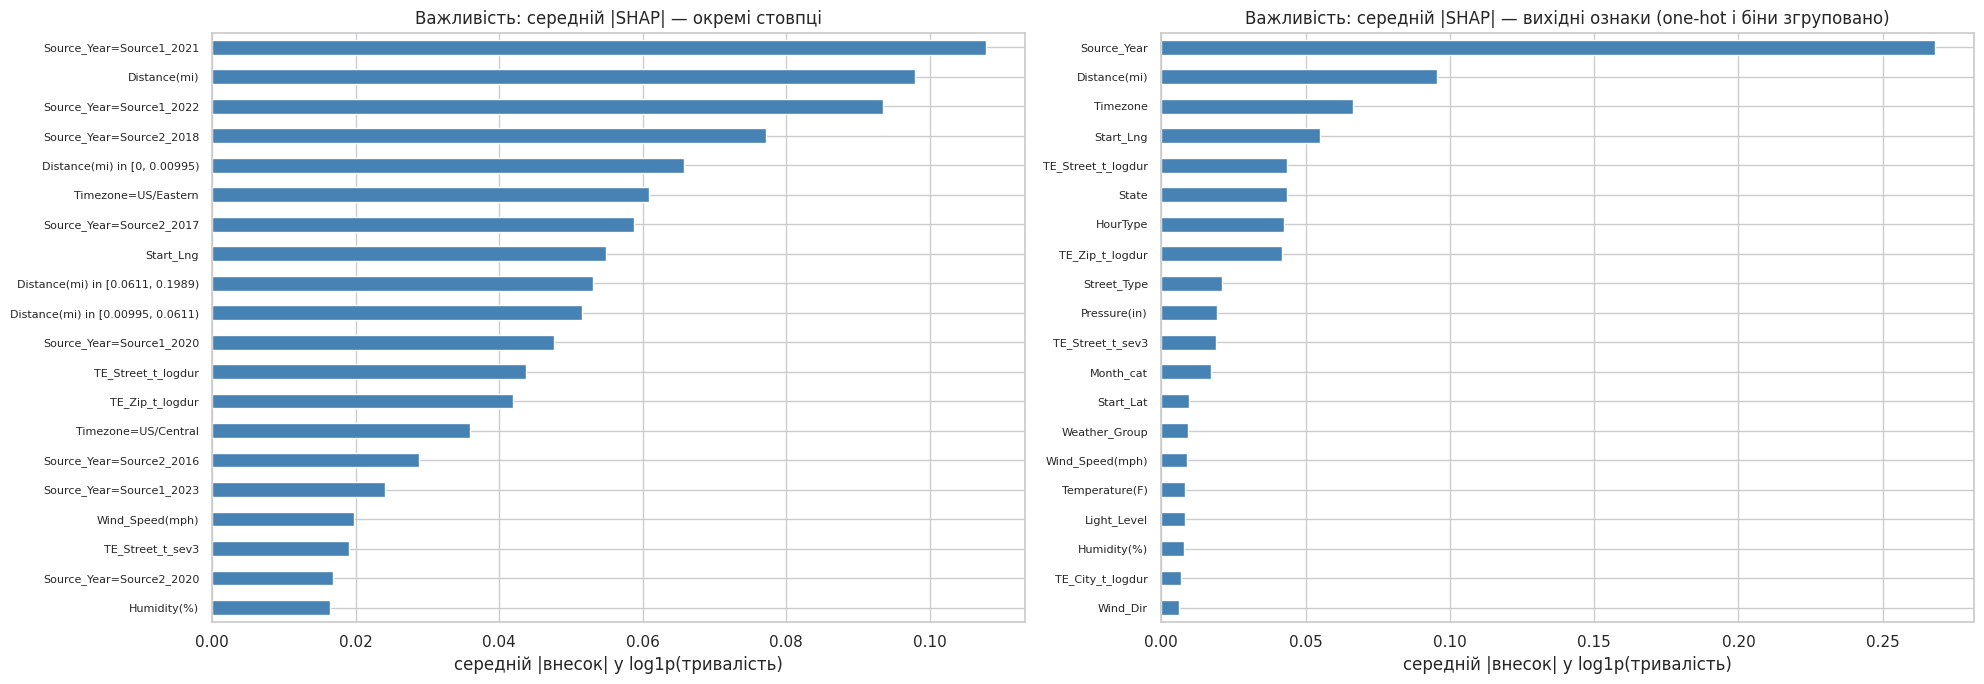

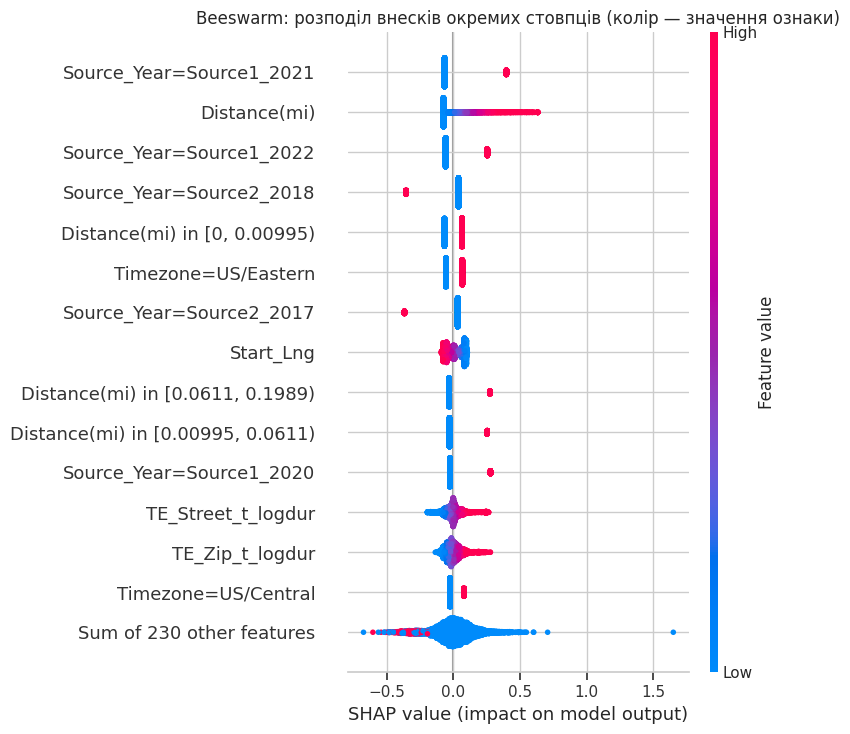

,середній |SHAP|
Source_Year,0.2682
Distance(mi),0.0956
Timezone,0.0663
Start_Lng,0.0549
TE_Street_t_logdur,0.0437
State,0.0437
HourType,0.0427
TE_Zip_t_logdur,0.0419
Street_Type,0.0209
Pressure(in),0.0192


In [12]:
import shap

coef, intercept = model.coefficients.toArray(), model.intercept
background = np.array([r["features"].toArray() for r in
                       train.sample(fraction=min(1.0, 3_000 / N["train"]), seed=SEED).limit(2_000).select("features").collect()])
explain_rows = (model.transform(DECILES.transform(test)
                                .sampleBy("decile", {float(d): 5_000 / N["test"] for d in range(len(DECILE_SPLITS) - 1)}, seed=SEED))
                .select("features", "prediction").collect())
X_explain = np.array([r["features"].toArray() for r in explain_rows])
pred_spark = np.array([r["prediction"] for r in explain_rows])
print(f"Фон: {len(background):,} записів train; вибірка SHAP: {len(X_explain):,} записів test")

explainer = shap.LinearExplainer((coef, intercept), shap.maskers.Independent(background, max_samples=len(background)))
sv = explainer(X_explain)
sv.feature_names = FEATURES
assert np.allclose(sv.base_values + sv.values.sum(axis=1), pred_spark, atol=1e-4), "база + внески ≠ прогноз Spark"


def feature_group(name):
    if name.startswith("DoW_"):
        return "DayOfWeek"
    for sep in ("=", " in ["):
        if sep in name:
            return name.split(sep)[0]
    return name


GROUPS = [feature_group(f) for f in FEATURES]
by_column = pd.Series(np.abs(sv.values).mean(axis=0), index=FEATURES).sort_values(ascending=False)
by_group = pd.DataFrame(sv.values, columns=FEATURES).T.groupby(GROUPS).sum().T.abs().mean().sort_values(ascending=False)

fig, axes = plt.subplots(1, 2, figsize=(20, 7))
for ax, imp, title in [(axes[0], by_column, "окремі стовпці"), (axes[1], by_group, "вихідні ознаки (one-hot і біни згруповано)")]:
    imp.head(20)[::-1].plot.barh(ax=ax, color="steelblue")
    ax.set_title(f"Важливість: середній |SHAP| — {title}")
    ax.set_xlabel("середній |внесок| у log1p(тривалість)")
    ax.tick_params(axis="y", labelsize=8)
plt.tight_layout()
plt.show()

shap.plots.beeswarm(sv, max_display=15, show=False)
plt.title("Beeswarm: розподіл внесків окремих стовпців (колір — значення ознаки)")
plt.tight_layout()
plt.show()
by_group.head(20).round(4).to_frame("середній |SHAP|")

## Збереження моделі

Spark-модель зберігається у власному форматі (`model.write()`, тека з метаданими й parquet коефіцієнтів) — її читає `LinearRegressionModel.load`. Поруч — коефіцієнти у joblib, щоб прогнозувати без Spark.

In [13]:
from pyspark.ml.regression import LinearRegressionModel

spark_path = MODELS_DIR / "regression_linear_spark"
model.write().overwrite().save(str(spark_path))
assert np.allclose(LinearRegressionModel.load(str(spark_path)).coefficients.toArray(), coef)

path = MODELS_DIR / "regression_linear_spark.joblib"
joblib.dump({"spark_model": spark_path.name, "coef": coef, "intercept": intercept, "params": best_params, "features": FEATURES,
             "target": "Log_Duration", "inverse": "expm1", "predict": "expm1(X @ coef + intercept)"}, path)
print("Збережено:", spark_path.name, "і", path.name)
spark.stop()

Збережено: regression_linear_spark і regression_linear_spark.joblib


## Висновки

| Модель (test) | R² (log) | RMSE (log) | MAE, хв | MedAE, хв | MAPE, % (хв) |
|---|---|---|---|---|---|
| Baseline — середнє | 0.000 | 0.709 | 48.1 | 34.0 | 65.1 |
| **LinearRegression (Ridge, `regParam = 0.001`)** | **0.352** | **0.571** | **37.7** | **19.4** | **50.7** |

* Модель пояснює **35% розкиду** логарифма тривалості й зменшує медіанну похибку з 34 до **19 хв** (−43%), середню — з 48 до 38 хв.
* **Гіперпараметри.** За 5-fold CV на підвибірці 99 915 записів найкраща — слабка L2-регуляризація `regParam = 0.001` (RMSE log 0.5697 ± 0.0014, R² 0.352 ± 0.004); Ridge 0.01 і Lasso 0.001 практично такі самі, сильніший штраф погіршує якість (Lasso 0.1: R² 0.20). **МНК без регуляризації на підвибірці нестабільний:** в одному з 5 фолдів RMSE ≈ 0.77 (звідси std 0.08). Ймовірна причина — на 80 000 записах частина рідкісних one-hot стовпців і бінів майже вироджена, і нормальні рівняння без штрафу дають для них величезні коефіцієнти. Ледь помітний штраф L2 це прибирає, а на повному train (4.5 млн записів) регуляризація на якість не впливає — метрики ті самі, що й у МНК зі scikit-learn у попередній версії ноутбука (R² test 0.352, MedAE 19.4 хв).
* **Перенавчання немає:** R² на train / valid / test — 0.353 / 0.353 / 0.352, RMSE (log) — 0.570 / 0.570 / 0.571; відсутність розриву між train і test підтверджує, що групове розбиття й out-of-fold target encoding не дали витоку.
* **Spark на великих даних:** `LinearRegression` (нормальні рівняння) навчається за один розподілений прохід по 4.5 млн записів — ~45 с, без копії матриці ознак у пам'яті й без порційного МНК, потрібного для scikit-learn; увесь ноутбук у Docker — ~5 хв.
* **Де модель помиляється:** типові тривалості прогнозуються близько до факту (60–120 хв, 28% записів: медіана прогнозу 78 хв проти 79 фактичних), короткі події (≤ 30 хв) переоцінюються (42 проти 30 хв), а довгі систематично **недооцінюються** (240–480 хв: прогноз ~102 хв проти 311). Це «стягування до середнього», властиве лінійній моделі: рідкісні тривалі події не вирізняються ознаками, доступними на момент ДТП. Вертикальні смуги на графіку «факт vs прогноз» — шаблонні значення джерел (≈30 / 45 / 60 хв), які ознаки не пояснюють.
* **SHAP:** найсильніша ознака — `Source_Year` (середній |SHAP| 0.27 — у 2.8 раза більше за наступну): джерело й рік визначають спосіб фіксації часу завершення. Далі — протяжність ділянки `Distance(mi)`, часовий пояс `Timezone` і довгота `Start_Lng` (обидві описують захід / схід країни, тож ділять між собою один ефект), історична тривалість ДТП на вулиці й індексі (`TE_Street_t_logdur`, `TE_Zip_t_logdur`), `State`, `HourType`.

**Нові дані: невідомий рік джерела.** `Source_Year` прив'язана до років train. Для запису з новим роком (наприклад, `Source1_2026`) **замінюємо `Source_Year` на останній відомий рік того ж джерела** (`Source1_2023`, `Source2_2022`, `Source3_2022`; див. `metadata.json` → `unseen_source_year`) — інакше запис або відкинеться, або буде сприйнятий як референсна категорія `Source3_2016` з іншим режимом фіксації часу завершення. Для класифікації перевірка «на майбутньому» підтвердила, що з цим правилом якість на новому році не падає (accuracy 0.969 проти 0.744 без нього); правило коректне, поки джерело не змінює спосіб фіксації даних.

**Що могло б покращити якість:** нелінійні моделі (градієнтний бустинг, наприклад `GBTRegressor` у Spark) для взаємодій ознак і довгого хвоста; окремі моделі для джерел із різними режимами фіксації часу.

Модель збережено: `data/models/regression_linear_spark/` (`LinearRegressionModel.load`; прогноз у хвилинах — `expm1(prediction)`) і коефіцієнти в `data/models/regression_linear_spark.joblib` (прогноз без Spark — `expm1(X @ coef + intercept)`).